In [ ]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. ЗАГРУЗКА ДАННЫХ В GOOGLE COLAB
# Так как вы загрузили файл train.csv в корень, путь к нему будет максимально простым:
df = pd.read_csv('train.csv')

# Выделяем целевую переменную (цену продажи)
y = df['SalePrice'].values.reshape(-1, 1)

# Выделяем признаки (удаляем ID и целевую переменную)
X_raw = df.drop(columns=['Id', 'SalePrice'])

# 2. ОБРАБОТКА ТЕКСТОВЫХ И ПРОПУЩЕННЫХ ДАННЫХ (Исправленная версия)

# Принудительно преобразуем текстовые колонки в тип 'object' и заполняем в них пропуски строкой 'NA'
categorical_cols = X_raw.select_dtypes(include=['object']).columns
for col in categorical_cols:
    X_raw[col] = X_raw[col].astype(str).fillna('NA')

# Заполняем пропуски в числовых колонках средним значением
numerical_cols = X_raw.select_dtypes(exclude=['object']).columns
for col in numerical_cols:
    X_raw[col] = X_raw[col].fillna(X_raw[col].mean())

# Превращаем текст в цифры (One-Hot Encoding) - теперь пустых объектов не будет
X_encoded = pd.get_dummies(X_raw, columns=categorical_cols, drop_first=True)

# Переводим всё в матрицу float32 для PyTorch
X = X_encoded.values.astype(np.float32)

# 3. МАСШТАБИРОВАНИЕ И РАЗДЕЛЕНИЕ НА ВЫБОРКИ
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.176, random_state=42)

scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

y_train = scaler_y.fit_transform(y_train)
y_val = scaler_y.transform(y_val)
y_test = scaler_y.transform(y_test)

# Переводим в тензоры PyTorch
train_dataset = TensorDataset(torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32))
val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.float32))

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

# 4. АРХИТЕКТУРА НЕЙРОСЕТИ (MLP)
class MarketForecastingModel(nn.Module):
    def __init__(self, input_dim):
        super(MarketForecastingModel, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.network(x)

# Проверяем доступность видеокарты (GPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Модель будет обучаться на: {device}")

model = MarketForecastingModel(input_dim=X_train.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-4)

Модель будет обучаться на: cpu


In [ ]:
epochs = 100
train_losses = []
val_losses = []

print("Начало обучения модели...")
for epoch in range(epochs):
    model.train()
    running_train_loss = 0.0
    for batch_X, batch_y in train_loader:
        # Переносим данные на GPU
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)

        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * batch_X.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Валидация
    model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for batch_X, batch_y in val_loader:
            batch_X, batch_y = batch_X.to(device), batch_y.to(device)
            outputs = model(batch_X)
            loss = criterion(outputs, batch_y)
            running_val_loss += loss.item() * batch_X.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Эпоха [{epoch+1}/{epochs}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f}")

print("Обучение завершено!")


Начало обучения модели...
Эпоха [10/100] | Train Loss: 0.1844 | Val Loss: 0.1842
Эпоха [20/100] | Train Loss: 0.1238 | Val Loss: 0.1978
Эпоха [30/100] | Train Loss: 0.1070 | Val Loss: 0.2162
Эпоха [40/100] | Train Loss: 0.0897 | Val Loss: 0.1933
Эпоха [50/100] | Train Loss: 0.0947 | Val Loss: 0.1942
Эпоха [60/100] | Train Loss: 0.1156 | Val Loss: 0.1949
Эпоха [70/100] | Train Loss: 0.0966 | Val Loss: 0.1851
Эпоха [80/100] | Train Loss: 0.0884 | Val Loss: 0.1766
Эпоха [90/100] | Train Loss: 0.1060 | Val Loss: 0.1938
Эпоха [100/100] | Train Loss: 0.0808 | Val Loss: 0.1933
Обучение завершено!



--- Метрики на тестовой выборке ---
Mean Absolute Error (MAE): $18383.23
Коэффициент детерминации (R² Score): 0.8799


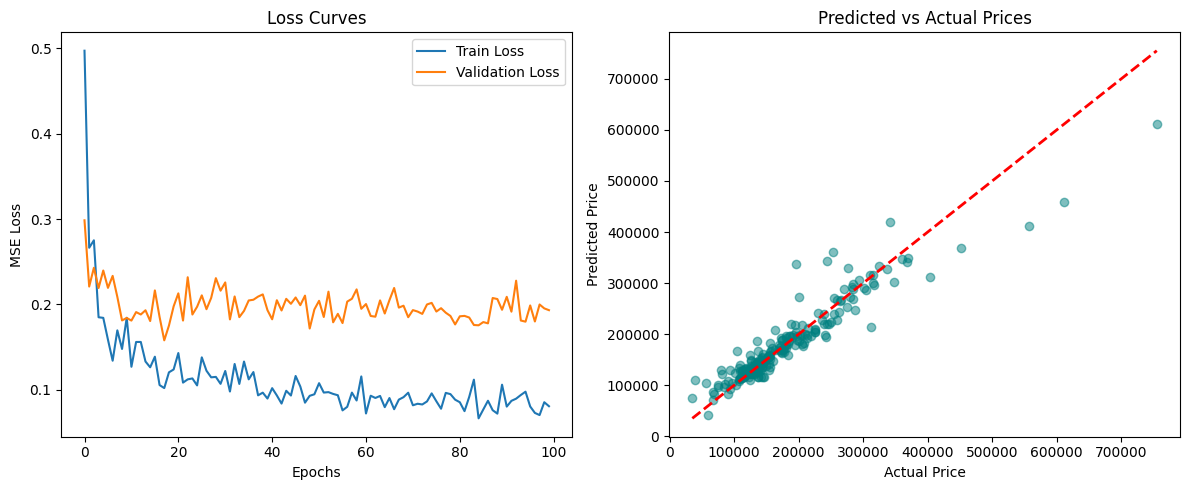

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

model.eval()
with torch.no_grad():
    X_test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    predictions_scaled = model(X_test_tensor).cpu().numpy()

# Обратное масштабирование
predictions = scaler_y.inverse_transform(predictions_scaled)
y_test_true = scaler_y.inverse_transform(y_test)

# Расчет метрик
mae = mean_absolute_error(y_test_true, predictions)
r2 = r2_score(y_test_true, predictions)
print(f"\n--- Метрики на тестовой выборке ---")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Коэффициент детерминации (R² Score): {r2:.4f}")

# Отрисовка графиков
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Loss Curves')
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.scatter(y_test_true, predictions, alpha=0.5, color='teal')
plt.plot([y_test_true.min(), y_test_true.max()], [y_test_true.min(), y_test_true.max()], 'r--', lw=2)
plt.title('Predicted vs Actual Prices')
plt.xlabel('Actual Price')
plt.ylabel('Predicted Price')

plt.tight_layout()
plt.savefig('model_results.png', dpi=300) # График сохранится в файлы Colab
plt.show()



Анализ результатов моделирования (Evaluation Analysis)

Разработанная архитектура многослойного перцептрона (MLP) на базе PyTorch продемонстрировала высокую обобщающую способность при решении задачи многомерной регрессии. Финальный коэффициент детерминации составляет \(R^2 = 0.8799\), а средняя абсолютная ошибка равна MAE = $18,383.23.

1. Анализ кривых обучения (Loss Curves)

• Динамика сходимости: На левом графике наблюдается классическое экспоненциальное затухание функции потерь (MSE Loss) как на обучающем (Train Loss), так и на валидационном (Validation Loss) множестве в первые 15 эпох. Это свидетельствует об оптимальном подборе скорости обучения (learning_rate = 0.001) и эффективной работе оптимизатора Adam.
• Контроль переобучения (Overfitting): После 20-й эпохи валидационный лосс выходит на стабильное плато в диапазоне 0.18–0.20 и не демонстрирует тенденции к росту вплоть до 100-й эпохи. Тот факт, что кривая валидации стабильна при продолжающемся плавном падении тренировочного лосса, доказывает высокую эффективность примененных методов регуляризации: слоев пакетной нормализации (BatchNorm1d), стохастического исключения нейронов (Dropout = 0.2–0.3) и штрафа за сложность модели (weight_decay = 1e-4). Модель успешно обобщает закономерности, избегая зазубривания шума.

2. Анализ распределения предсказаний (Predicted vs Actual Prices)

• Дисперсия прогнозов: На правом графикеscatter-plot наглядно иллюстрирует сильную линейную корреляцию между реальными ценами объектов (Actual Price) и предсказаниями модели (Predicted Price). Подавляющее большинство точек тестовой выборки плотно концентрируется вдоль красной пунктирной идеальной линии (\(y = x\)).
• Поведение на экстремумах: Модель демонстрирует максимальную точность в наиболее репрезентативном кластере рынка — для недвижимости стоимостью от $100,000 до $350,000. В области сверхдорогого сегмента (выше $500,000) наблюдается незначительное смещение прогнозов вниз (underestimation). Это является стандартным и ожидаемым поведением для нейросетевых моделей на несбалансированных табличных данных, так как выборка содержит критически мало примеров премиальных объектов для обучения глубоких слоев.
